# Оценка условных преподавателей: воспроизводимый эксперимент

**Бакулин Александр Максимович.** Автоматизация процессов оценки эффективности работы сотрудника университета с применением интеллектуального анализа данных.

Набор и цели **синтетические**, выбранные пользователем для разработки. Это проверка программного конвейера, а не исследование реальной эффективности сотрудников. Формальное требование реальных данных остаётся открытым. Все шаги выполняются из исходного CSV; готовые веса не используются для обучения.

In [1]:
from pathlib import Path
import os, json, platform, tempfile
import numpy as np
ROOT = Path.cwd()
if not (ROOT / "main.py").exists():
    ROOT = ROOT.parent
assert (ROOT / "data/simulation-v1/synthetic_employees.csv").is_file()
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".local/matplotlib"))
(ROOT / ".local").mkdir(exist_ok=True)
temporary = tempfile.TemporaryDirectory(prefix="notebook-", dir=ROOT / ".local")
RUN = Path(temporary.name)
from university_analytics.data import Dataset, load_dataset
from university_analytics.experiment import ExperimentConfig
from university_analytics.quality import profile_dataset
from university_analytics.splitting import split_dataset, write_splits
from university_analytics.baselines import load_split_bundle, run_baseline_experiment
from university_analytics.tuning import load_network_grid, run_neural_experiment
from university_analytics.comparison import run_comparison
from university_analytics.diagnostics import run_diagnostics
from university_analytics.plots import export_plots
from university_analytics.portable import PortableNetwork
print({"python": platform.python_version(), "numpy": np.__version__, "назначение": "development_demo_only"})

{'python': '3.14.7', 'numpy': '2.5.5', 'назначение': 'development_demo_only'}


## Данные и явная цель

1500 условных преподавателей наблюдаются два периода. Идентификатор сотрудника группирует наблюдения, цель `efficiency_level` имеет три класса. Связанный `efficiency_score`, период и признак происхождения исключены из входов. Числовые и категориальные признаки заданы контрактом, а не выбираются по test.

In [2]:
raw = load_dataset(str(ROOT / "data/simulation-v1/synthetic_employees.csv"))
data = Dataset(raw.columns, raw.rows, "bundled-simulation", raw.sha256, raw.origin_kind)
config = ExperimentConfig.from_file(ROOT / "data/simulation-v1/experiment.json")
config.check_columns(data)
profile = profile_dataset(data, config.target)
assert profile["data_origin"] == "synthetic"
print({key: profile[key] for key in ["row_count", "column_count", "duplicate_rows", "data_origin", "sha256"]})
print({"цель": config.target, "группа": config.group_column, "исключения": config.excluded_columns})

{'row_count': 3000, 'column_count': 16, 'duplicate_rows': 0, 'data_origin': 'synthetic', 'sha256': '698dbfc7709f492a58f8ee1dcba83d8355173ad0ebd0ae8d257e49c5dd1e75af'}
{'цель': 'efficiency_level', 'группа': 'employee_id', 'исключения': ('efficiency_score', 'source_kind', 'period_id')}


## Независимое разбиение и подготовка

Разбиение 70/15/15 выполняется по сотрудникам с seed 42. Медианы, масштабирование и словари категорий оцениваются только на train. Validation выбирает модель и эпоху; test не участвует в выборе. Macro-F1 использует фиксированные классы train и не теряет нулевой вклад отсутствующего класса.

In [3]:
split = split_dataset(data, seed=config.seed, group_column=config.group_column)
write_splits(data, split, RUN / "splits", target=config.target)
parts, manifest = load_split_bundle(RUN / "splits", config)
index = data.columns.index(config.group_column)
groups = {name: {row[index] for row in part.rows} for name, part in parts.items()}
assert not (groups["train"] & groups["validation"] or groups["train"] & groups["test"] or groups["validation"] & groups["test"])
print({name: {"строк": len(part.rows), "сотрудников": len(groups[name])} for name, part in parts.items()})

{'train': {'строк': 2100, 'сотрудников': 1050}, 'validation': {'строк': 450, 'сотрудников': 225}, 'test': {'строк': 450, 'сотрудников': 225}}


## Базовые модели

Сравниваются наиболее частый класс и логистическая регрессия со сбалансированными весами. Нейросеть должна сравниваться с ними по одному контракту и одному разбиению, а не только с Accuracy большинства.

In [4]:
baseline = run_baseline_experiment(RUN / "splits", config, RUN / "baseline")
print({"выбрана": baseline["selected_model"], "критерий": baseline["selection_metric"], "метрики": baseline["metrics"]})

{'выбрана': 'linear', 'критерий': 'macro_f1', 'метрики': {'dummy': {'train': {'accuracy': 0.589047619047619, 'macro_f1': 0.24712815902507243}, 'validation': {'accuracy': 0.5488888888888889, 'macro_f1': 0.23625059780009564}, 'test': {'accuracy': 0.5888888888888889, 'macro_f1': 0.24708624708624707}}, 'linear': {'train': {'accuracy': 0.7633333333333333, 'macro_f1': 0.7542628136149666}, 'validation': {'accuracy': 0.8022222222222222, 'macro_f1': 0.7976393285100158}, 'test': {'accuracy': 0.76, 'macro_f1': 0.7470509302405853}}}}


## DL: компактная табличная MLP

Два скрытых слоя 32/16 либо 64/32, ReLU, Adam, L2 и балансировка классов. Сетка содержит три варианта. Каждая эпоха обучается только на train, лучший checkpoint выбирается по внешней validation macro-F1. Ранняя остановка ограничивает лишние эпохи; test оценивается после окончательного выбора конфигурации.

In [5]:
grid = load_network_grid(ROOT / "configs/network-grid-v1.json", config.seed)
neural = run_neural_experiment(RUN / "splits", config, grid, RUN / "neural")
print({"архитектура": neural["architecture"], "эпоха": neural["best_epoch"], "метрики": neural["metrics"]})

{'архитектура': {'input_units': 16, 'hidden_layers': [32, 16], 'output_units': 3, 'output_activation': 'softmax', 'class_labels': ['высокая', 'низкая', 'средняя'], 'activation': 'relu', 'parameter_count': 1123}, 'эпоха': 17, 'метрики': {'neural': {'train': {'accuracy': 0.7685714285714286, 'macro_f1': 0.7610574764060253}, 'validation': {'accuracy': 0.7955555555555556, 'macro_f1': 0.7957974717941484}, 'test': {'accuracy': 0.7844444444444445, 'macro_f1': 0.7714011030125532}}}}


## Сравнение семейств

Более высокий test не меняет выбранный критерий. Если линейная модель лучше на validation, она остаётся выбранной даже при более высоком test у DL. Синтетические метрики не доказывают выполнение требования качества на реальных данных.

In [6]:
comparison = run_comparison([RUN / "baseline", RUN / "neural"], RUN / "comparison")
chosen = next(item for item in comparison["entries"] if item["id"] == comparison["selected"])
print({"выбранное_семейство": chosen["experiment"], "модель": chosen["model"], "метрика_выбора": comparison["selection_metric"]})
for item in comparison["entries"]:
    print(item["model"], {part: round(item["metrics"][part]["macro_f1"], 5) for part in ["train", "validation", "test"]})

{'выбранное_семейство': 'baseline', 'модель': 'linear', 'метрика_выбора': 'macro_f1'}
dummy {'train': 0.24713, 'validation': 0.23625, 'test': 0.24709}
linear {'train': 0.75426, 'validation': 0.79764, 'test': 0.74705}
neural {'train': 0.76106, 'validation': 0.7958, 'test': 0.7714}


## Ошибки и история обучения нейросети

Матрица показывает, какие искусственные классы смешиваются. Категориальные срезы с малыми выборками скрываются. Эти срезы описательные; они не доказывают причинность или справедливость модели. Ниже графики именно DL, независимо от выбранного семейства.

{'ошибок_test': 97, 'классы': ['высокая', 'низкая', 'средняя']}


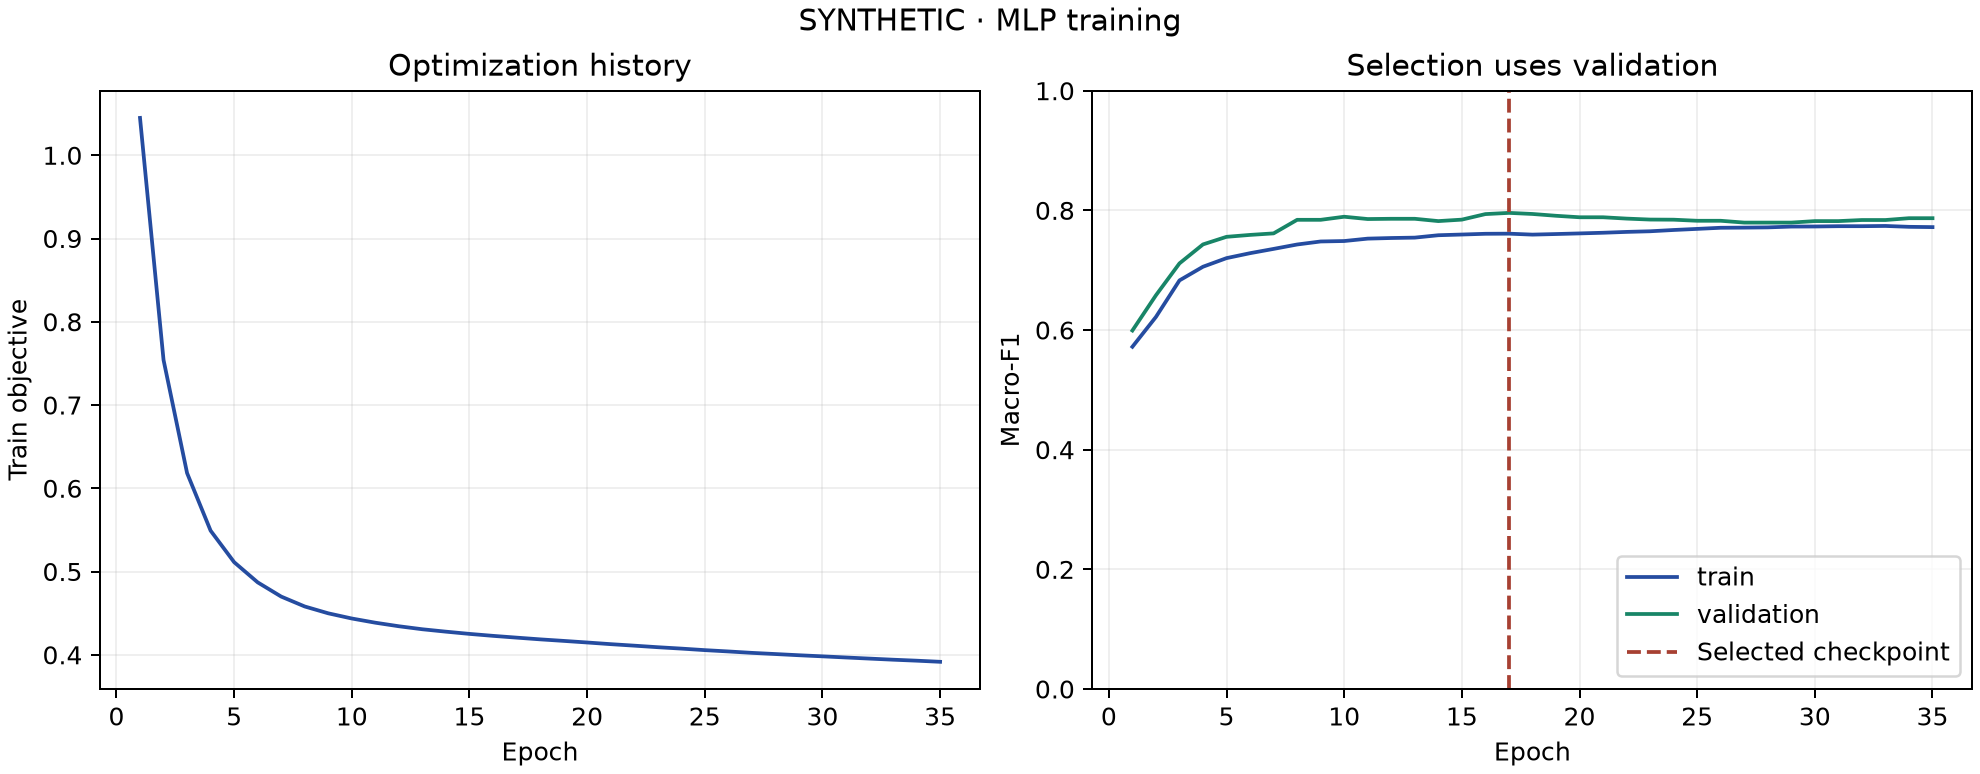

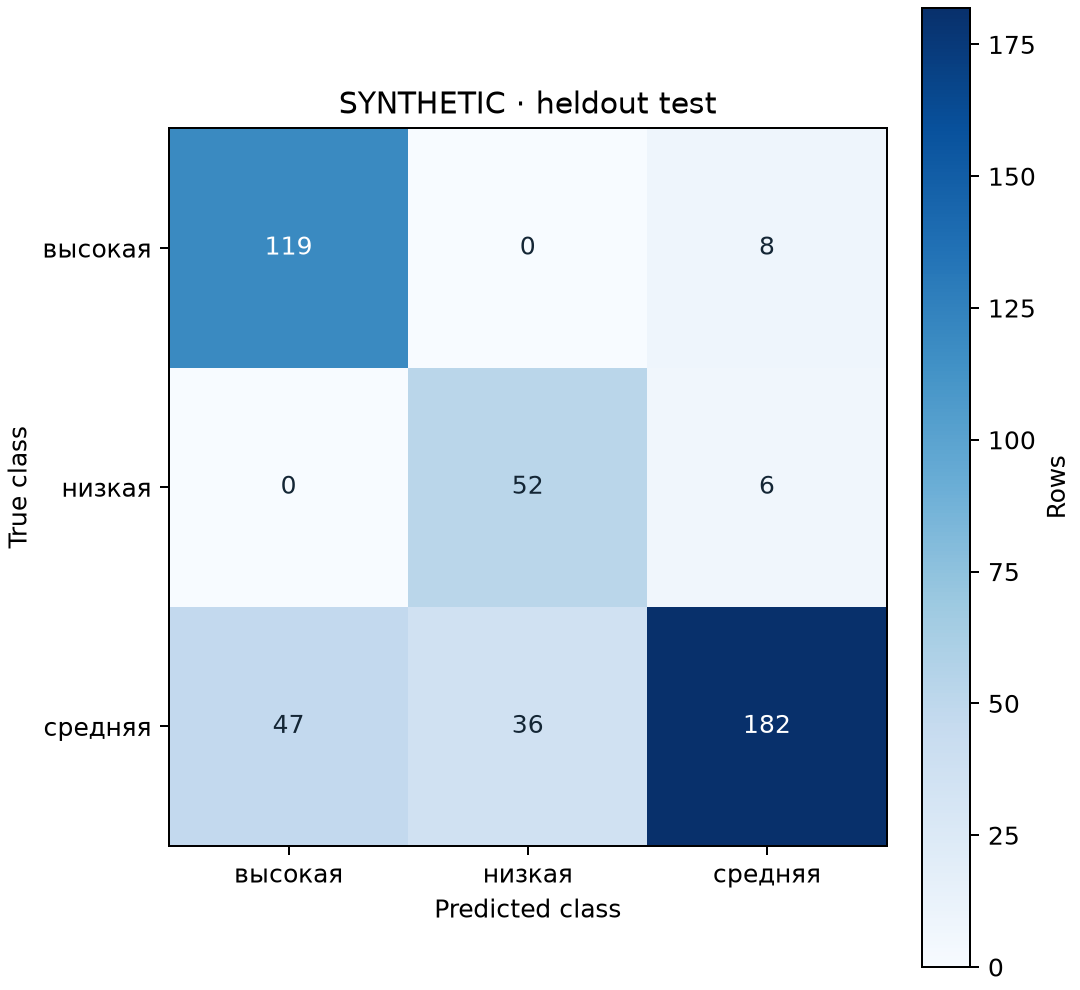

In [7]:
diagnostic = run_diagnostics(RUN / "splits", RUN / "neural", RUN / "diagnostics")
export_plots(RUN / "neural", RUN / "diagnostics", RUN / "figures")
print({"ошибок_test": diagnostic["partitions"]["test"]["error_count"], "классы": diagnostic["partitions"]["test"]["labels"]})
from IPython.display import display, Image
display(Image(filename=str(RUN / "figures/training.png"), width=900))
display(Image(filename=str(RUN / "figures/test-confusion.png"), width=550))

## Применение выбранной модели без цели и повторного обучения

JSON содержит только параметры и числовые веса. При прогнозе не загружаются Python/pickle-объекты. Пропуски и неизвестные категории обрабатываются сохранёнными train-статистиками.

In [8]:
family = "baseline" if chosen["id"].startswith("1:") else "neural"
model = PortableNetwork.from_file(RUN / family / "model.json")
columns = tuple(name for name in data.columns if name not in {config.target, "efficiency_score"})
indices = [data.columns.index(name) for name in columns]
incoming = Dataset(columns, tuple(tuple(row[i] for i in indices) for row in parts["test"].rows[:5]), "prediction-demo", "0"*64, "synthetic")
probabilities = model.predict_proba(incoming)
assert probabilities.shape == (5, 3)
np.testing.assert_allclose(probabilities.sum(axis=1), 1, atol=1e-12)
print({"прогнозы": model.predict(incoming).tolist(), "назначение": model.intended_use})
print(np.round(probabilities, 4))

{'прогнозы': ['высокая', 'высокая', 'низкая', 'низкая', 'средняя'], 'назначение': 'development_demo_only'}
[[7.636e-01 3.000e-04 2.361e-01]
 [8.323e-01 1.000e-04 1.676e-01]
 [0.000e+00 9.453e-01 5.470e-02]
 [0.000e+00 9.444e-01 5.560e-02]
 [1.653e-01 2.700e-02 8.076e-01]]


## Итог и ограничения

Воспроизводятся загрузка, проверки, групповой split, baseline/DL, поиск, выбор по validation, ошибки, графики и JSON-применение. Математическое описание находится в `docs/MATHEMATICS.md`, проверки — в `docs/TESTING.md`.

Программный конвейер работает на симуляции. Реальные данные, предметная валидность оценки сотрудников и исследовательская применимость остаются отдельными критериями. Данные и цель не подменяются утверждением о реальном университете. Временные артефакты этого запуска очищаются; постоянные эксперименты сохраняются командами CLI либо через GUI.

In [9]:
assert comparison["intended_use"] == "development_demo_only"
assert comparison["selection_partition"] == "validation"
temporary.cleanup()
print("Сквозной запуск завершён. Синтетическое происхождение сохранено.")

Сквозной запуск завершён. Синтетическое происхождение сохранено.
